### Task 1: SVM Classifier – Pop vs Classical Music

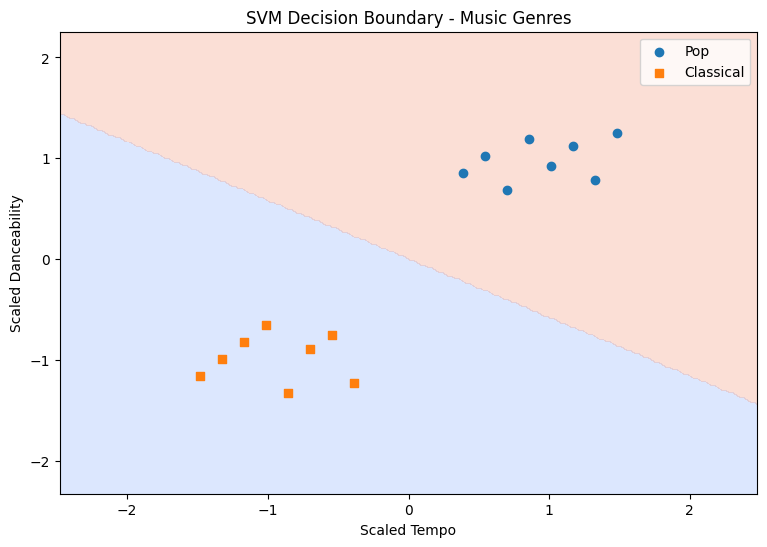

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Create sample music dataset
data = {
    "Tempo": [120, 125, 130, 135, 140, 145, 150, 155,
              60, 65, 70, 75, 80, 85, 90, 95],

    "Danceability": [0.80, 0.85, 0.75, 0.90, 0.82, 0.88, 0.78, 0.92,
                     0.20, 0.25, 0.30, 0.35, 0.15, 0.28, 0.32, 0.18],

    "Genre": ["Pop", "Pop", "Pop", "Pop", "Pop", "Pop", "Pop", "Pop",
              "Classical", "Classical", "Classical", "Classical",
              "Classical", "Classical", "Classical", "Classical"]
}

df = pd.DataFrame(data)

# Features and target
X = df[["Tempo", "Danceability"]]
y = df["Genre"]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train SVM
model = SVC(kernel="linear")
model.fit(X_scaled, y)

# Create decision boundary
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1

import numpy as np

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z == "Pop", alpha=0.3, cmap="coolwarm")

plt.scatter(
    X_scaled[y == "Pop", 0],
    X_scaled[y == "Pop", 1],
    label="Pop",
    marker="o"
)

plt.scatter(
    X_scaled[y == "Classical", 0],
    X_scaled[y == "Classical", 1],
    label="Classical",
    marker="s"
)

plt.xlabel("Scaled Tempo")
plt.ylabel("Scaled Danceability")
plt.title("SVM Decision Boundary - Music Genres")
plt.legend()
plt.show()

### Task 2: Flipkart Product Review Classification using Linear SVM

In [2]:
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Sample product reviews
data = {
    "Review": [
        "Excellent product and amazing quality",
        "Very good product and fast delivery",
        "I love this product",
        "Amazing quality and value for money",
        "Product is very useful",
        "Excellent and beautiful product",
        "Worst product and poor quality",
        "Very bad product",
        "Product is damaged and useless",
        "Poor quality and slow delivery",
        "Not good and very disappointing",
        "I hate this product",
        "Amazing product and great experience",
        "Bad quality and waste of money",
        "Very happy with this purchase",
        "Terrible product and poor service",
        "Good quality and excellent performance",
        "Not worth buying",
        "Fantastic product",
        "Completely disappointed"
    ],

    "Sentiment": [
        "Positive", "Positive", "Positive", "Positive",
        "Positive", "Positive", "Negative", "Negative",
        "Negative", "Negative", "Negative", "Negative",
        "Positive", "Negative", "Positive", "Negative",
        "Positive", "Negative", "Positive", "Negative"
    ]
}

df = pd.DataFrame(data)

# Convert text into numerical features
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df["Review"])

y = df["Sentiment"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Train Linear SVM
model = SVC(kernel="linear")
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Accuracy
print("Linear SVM Accuracy:", accuracy_score(y_test, y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Predict a new review
new_review = ["Excellent product with amazing quality"]

new_review_vector = vectorizer.transform(new_review)

prediction = model.predict(new_review_vector)

print("New Review Prediction:", prediction[0])

Linear SVM Accuracy: 0.6

Classification Report:
              precision    recall  f1-score   support

    Negative       0.60      1.00      0.75         3
    Positive       0.00      0.00      0.00         2

    accuracy                           0.60         5
   macro avg       0.30      0.50      0.38         5
weighted avg       0.36      0.60      0.45         5

New Review Prediction: Positive


C:\Users\admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### Task 3: Compare Polynomial and RBF Kernels – IPL Dataset

In [3]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create sample IPL dataset
data = {
    "Runs": [450, 380, 520, 300, 250, 180, 600, 420,
             100, 150, 200, 80, 550, 480, 120, 90,
             350, 410, 160, 220, 500, 130, 390, 70],

    "Strike_Rate": [145, 135, 155, 125, 115, 110, 160, 140,
                    85, 95, 100, 75, 158, 150, 80, 70,
                    130, 142, 90, 105, 152, 88, 138, 65],

    "Average": [45, 38, 52, 30, 25, 18, 60, 42,
                10, 15, 20, 8, 55, 48, 12, 9,
                35, 41, 16, 22, 50, 13, 39, 7],

    "Performance": [
        "Good", "Good", "Good", "Good", "Good", "Good",
        "Good", "Good", "Poor", "Poor", "Poor", "Poor",
        "Good", "Good", "Poor", "Poor", "Good", "Good",
        "Poor", "Poor", "Good", "Poor", "Good", "Poor"
    ]
}

df = pd.DataFrame(data)

# Features and target
X = df[["Runs", "Strike_Rate", "Average"]]
y = df["Performance"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Polynomial Kernel
poly_model = SVC(kernel="poly", degree=3)
poly_model.fit(X_train_scaled, y_train)

poly_pred = poly_model.predict(X_test_scaled)

poly_accuracy = accuracy_score(y_test, poly_pred)

# RBF Kernel
rbf_model = SVC(kernel="rbf")
rbf_model.fit(X_train_scaled, y_train)

rbf_pred = rbf_model.predict(X_test_scaled)

rbf_accuracy = accuracy_score(y_test, rbf_pred)

# Compare accuracy
print("Polynomial Kernel Accuracy:", poly_accuracy)
print("RBF Kernel Accuracy:", rbf_accuracy)

if poly_accuracy > rbf_accuracy:
    print("Polynomial Kernel performed better.")
elif rbf_accuracy > poly_accuracy:
    print("RBF Kernel performed better.")
else:
    print("Both kernels performed equally.")

Polynomial Kernel Accuracy: 0.8333333333333334
RBF Kernel Accuracy: 1.0
RBF Kernel performed better.


### Task 4: Visualize SVM Margin and Support Vectors – Zomato Dataset

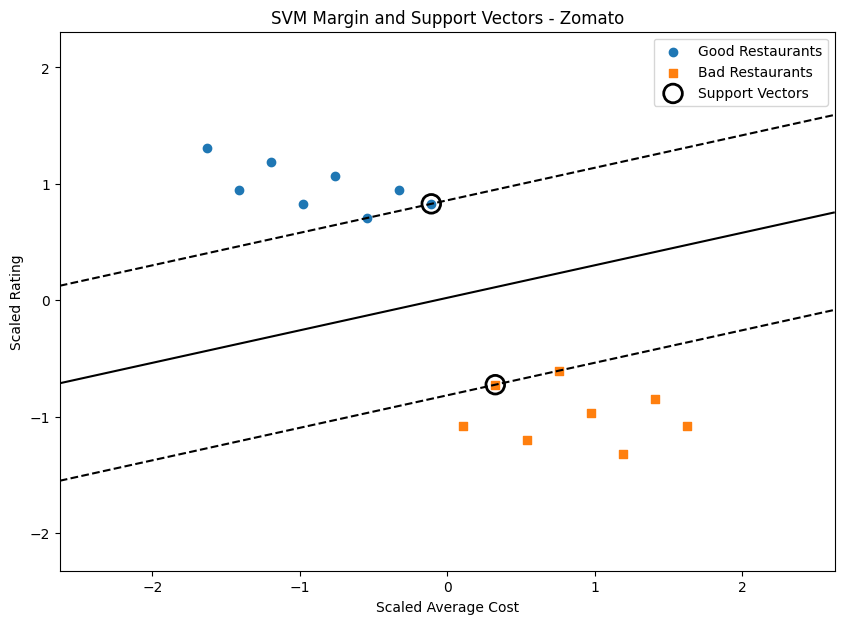

Number of Support Vectors: 2
Support Vectors:
[[ 0.32539569 -0.72430427]
 [-0.10846523  0.82884303]]


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Create sample Zomato dataset
data = {
    "Average_Cost": [100, 150, 200, 250, 300, 350, 400, 450,
                     500, 550, 600, 650, 700, 750, 800, 850],

    "Rating": [4.5, 4.2, 4.4, 4.1, 4.3, 4.0, 4.2, 4.1,
               2.5, 2.8, 2.4, 2.9, 2.6, 2.3, 2.7, 2.5],

    "Category": ["Good", "Good", "Good", "Good",
                 "Good", "Good", "Good", "Good",
                 "Bad", "Bad", "Bad", "Bad",
                 "Bad", "Bad", "Bad", "Bad"]
}

df = pd.DataFrame(data)

# Features and target
X = df[["Average_Cost", "Rating"]]
y = df["Category"]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train SVM with linear kernel
model = SVC(kernel="linear", C=1)
model.fit(X_scaled, y)

# Create mesh grid
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Predict decision values
Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary and margins
plt.figure(figsize=(10, 7))

plt.contour(
    xx, yy, Z,
    levels=[-1, 0, 1],
    colors="black",
    linestyles=["--", "-", "--"]
)

# Plot data points
plt.scatter(
    X_scaled[y == "Good", 0],
    X_scaled[y == "Good", 1],
    label="Good Restaurants",
    marker="o"
)

plt.scatter(
    X_scaled[y == "Bad", 0],
    X_scaled[y == "Bad", 1],
    label="Bad Restaurants",
    marker="s"
)

# Highlight support vectors
plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=180,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="Support Vectors"
)

plt.xlabel("Scaled Average Cost")
plt.ylabel("Scaled Rating")
plt.title("SVM Margin and Support Vectors - Zomato")
plt.legend()
plt.show()

# Display support vectors
print("Number of Support Vectors:", len(model.support_vectors_))
print("Support Vectors:")
print(model.support_vectors_)